# 03 – Station types from 24-hour net-flow profiles

**Question:** what kinds of stations are there, judged by *when* bikes pile up or run out? And how do these types sit inside the functional areas from notebook 02?

Each station gets a **48-dimensional profile**: its average net flow (arrivals − departures) for each hour of a weekday and of a weekend day, divided by the station's total daily activity. The division removes station size, so a quiet residential station and a busy one with the same daily rhythm look alike.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score as ari

from citibike import graph as G
from citibike import profiles as P
from citibike.paths import FIGURES, PROCESSED

FIGURES.mkdir(exist_ok=True)
from citibike.plots import CATEGORICAL, DIVERGING, NEUTRAL, TEXT_MUTED, diverging_colors, style_map

pd.set_option("display.width", 200)
comm = pd.read_parquet(PROCESSED / "station_communities.parquet").set_index("station_id")
ids = comm.index.to_numpy()                      # same stations as the graph analysis
st = pd.read_parquet(PROCESSED / "stations.parquet").set_index("station_id").loc[ids]
X = P.profile_matrix(ids)
print(X.shape)
X.iloc[:3, :8].round(4)

(2384, 48)


,wd00,wd01,wd02,wd03,wd04,wd05,wd06,wd07
station_id,,,,,,,,
1964.01,0.0075,0.0019,-0.0028,0.0009,0.0075,0.0028,-0.0009,-0.0084
2009.04,0.0015,-0.0030,-0.0008,-0.0015,-0.0015,-0.0008,-0.0038,-0.0143
2042.01,0.0046,0.0046,0.0011,0.0034,0.0034,0.0000,0.0011,-0.0069


## 1. Is there cluster structure at all? (PCA)

explained variance of the first 5 components: [0.367 0.084 0.05  0.039 0.032]  cumulative: [0.367 0.451 0.501 0.54  0.572]


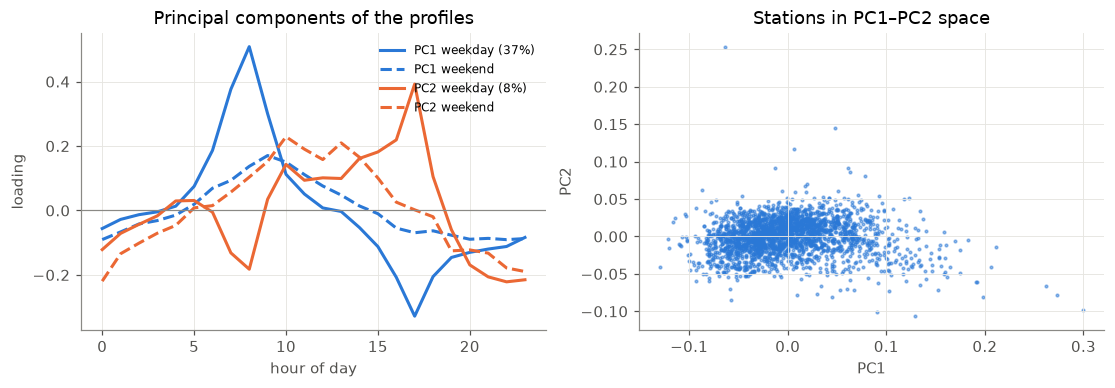

In [2]:
pca = PCA().fit(X)
ev = pca.explained_variance_ratio_
print("explained variance of the first 5 components:", ev[:5].round(3), " cumulative:", ev[:5].cumsum().round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
hours = np.arange(24)
for i, col in zip(range(2), CATEGORICAL):
    axs[0].plot(hours, pca.components_[i, :24], color=col, label=f"PC{i + 1} weekday ({ev[i]:.0%})")
    axs[0].plot(hours, pca.components_[i, 24:], color=col, ls="--", label=f"PC{i + 1} weekend")
axs[0].axhline(0, color=NEUTRAL, lw=0.8)
axs[0].set(xlabel="hour of day", ylabel="loading", title="Principal components of the profiles"); axs[0].legend(fontsize=8)
Z = pca.transform(X)
axs[1].scatter(Z[:, 0], Z[:, 1], s=3, color=CATEGORICAL[0], alpha=0.5)
axs[1].set(xlabel="PC1", ylabel="PC2", title="Stations in PC1–PC2 space");

**One axis dominates.** PC1 explains 37% of the variance and PC2 only 8%. PC1 is the *commuting axis*: a strong positive loading at 8 am and a negative one at 5 pm on weekdays, and almost nothing on weekends. Stations with a high PC1 score fill up in the morning and empty in the evening. PC2 picks out *daytime destinations*, which gain bikes from late morning until 5 pm and on weekend days and lose them in the evening. In the PC1–PC2 plane the stations form **one continuous cloud** with no separated groups. So we shouldn't expect the clustering to find well-separated types. It can only cut a continuum into sensible pieces.

## 2. Choosing k (Davies–Bouldin: lower is better; silhouette: higher is better)

davies_bouldin        silhouette        smallest_cluster       
method         kmeans   ward     kmeans   ward           kmeans   ward
k                                                                     
2               1.521  1.509      0.254  0.272            834.0  621.0
3               1.801  2.096      0.163  0.116            373.0  621.0
4               2.012  2.129      0.125  0.110            119.0  100.0
5               2.256  2.552      0.109  0.041            114.0  100.0
6               2.328  2.347      0.076  0.043             84.0    3.0
7               2.055  2.342      0.076  0.019              1.0    3.0
8               1.803  2.111      0.079  0.014              1.0    1.0
9               1.590  2.268      0.079  0.012              1.0    1.0
10              2.011  2.023      0.074  0.012              1.0    1.0

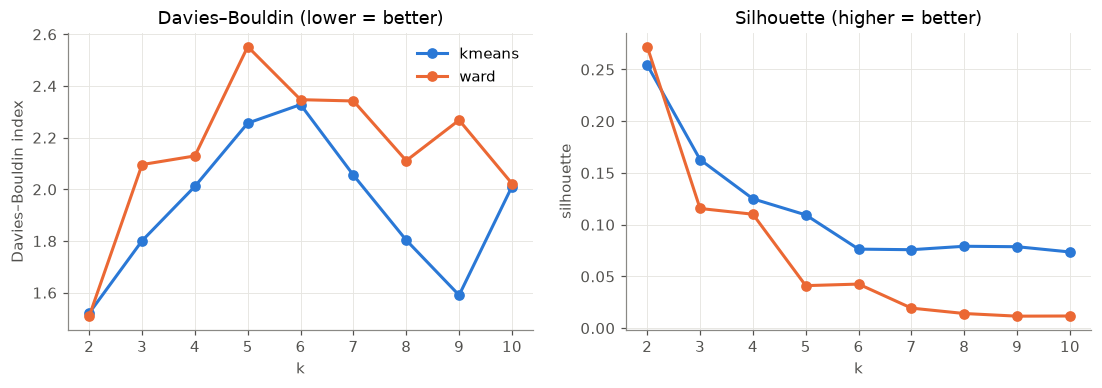

In [3]:
sel = P.k_selection(X, range(2, 11))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for m, col in zip(["kmeans", "ward"], CATEGORICAL):
    d = sel[sel.method == m]
    axs[0].plot(d.k, d.davies_bouldin, marker="o", color=col, label=m)
    axs[1].plot(d.k, d.silhouette, marker="o", color=col, label=m)
axs[0].set(xlabel="k", ylabel="Davies–Bouldin index", title="Davies–Bouldin (lower = better)")
axs[1].set(xlabel="k", ylabel="silhouette", title="Silhouette (higher = better)"); axs[0].legend()
sel.pivot(index="k", columns="method", values=["davies_bouldin", "silhouette", "smallest_cluster"]).round(3)

Both indices and both algorithms agree that **k = 2 is best** (silhouette 0.25–0.27, Davies–Bouldin ≈1.5). Beyond that the scores get steadily worse, and Ward starts producing clusters of 1–3 outlier stations from k = 6 (k-means from k = 7). A silhouette of 0.25 is weak: the two groups touch. This is consistent with the PCA, since the data are a continuum along the commuting axis, and k = 2 is simply "sources" vs "sinks", the split we expected.

In [4]:
for k in (2, 3, 4, 5):
    print(f"k={k}: ARI k-means vs Ward = {ari(P.cluster(X, k, 'kmeans'), P.cluster(X, k, 'ward')):.3f}")

k=2: ARI k-means vs Ward = 0.629


k=3: ARI k-means vs Ward = 0.401


k=4: ARI k-means vs Ward = 0.497


k=5: ARI k-means vs Ward = 0.374


k-means and Ward only partly agree (ARI 0.63 at k = 2 and 0.50 at k = 4). Where the two algorithms place the cut along the continuum depends on their objective, which is another sign that boundaries between types are soft. **We use k = 4 for the description below.** The indices prefer k = 2, but k = 4 separates the strong cases (job centres, clearly residential stations) from the large middle. It is still well above the point where clusters collapse into outliers, and the extra structure is easy to interpret. The k = 4 types should be read as *intervals on one axis*, not as natural groups.

## 3. The station types

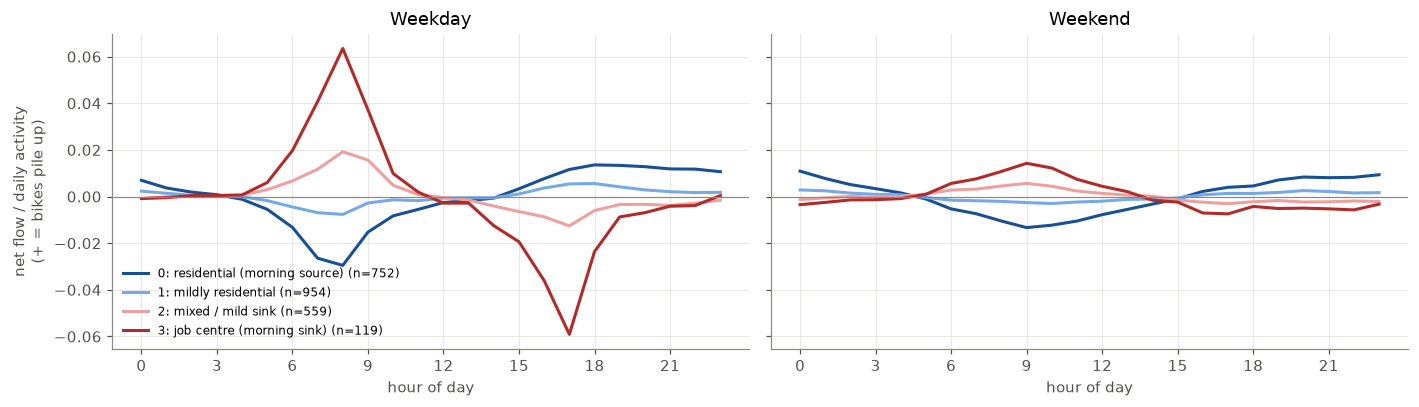

In [5]:
K = 4
labels = P.cluster(X, K, "kmeans")                  # 0 = strongest morning source ... K-1 = strongest morning sink
colors = diverging_colors(K)
names = {0: "residential (morning source)", 1: "mildly residential", 2: "mixed / mild sink", 3: "job centre (morning sink)"}
centroids = X.groupby(labels).mean()
fig, axs = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for c in range(K):
    n = (labels == c).sum()
    axs[0].plot(hours, centroids.loc[c].iloc[:24], color=colors[c], label=f"{c}: {names[c]} (n={n})")
    axs[1].plot(hours, centroids.loc[c].iloc[24:], color=colors[c])
for ax, t in zip(axs, ["Weekday", "Weekend"]):
    ax.axhline(0, color=NEUTRAL, lw=0.8); ax.set(title=t, xlabel="hour of day", xticks=range(0, 24, 3))
axs[0].set_ylabel("net flow / daily activity\n(+ = bikes pile up)")
axs[0].legend(fontsize=6.5, loc="lower left")
fig.tight_layout(); fig.savefig(FIGURES / "profile_types.pdf", bbox_inches="tight")

* **Job centres** (119 stations) gain bikes sharply from 6–10 am, about 6% of their daily trip ends per hour at the peak, and lose them again 3–7 pm. On weekends the pattern almost disappears.
* **Residential stations** (752) are the mirror image: they empty in the morning and refill in the evening and at night. On weekends they still lose bikes around midday, as people ride out.
* The two middle types are weaker versions of these.
* The weekday pattern is far stronger than the weekend one for every type, which matches notebook 02, where weekends looked like the full year and the morning rush was the exception.

In [6]:
summary = pd.DataFrame({"type": pd.Series(labels, index=ids).map(names), "trips_per_day": (st.departures + st.arrivals) / 365})
summary = summary.join(pd.read_parquet(PROCESSED / "station_areas.parquet").set_index("station_id")[["borough", "nta_name"]])
out = summary.groupby("type").agg(stations=("borough", "size"), median_trips_per_day=("trips_per_day", "median"),
                                  top_ntas=("nta_name", lambda s: ", ".join(s.value_counts().index[:4])))
out.loc[[names[c] for c in range(K)]]

,stations,median_trips_per_day,top_ntas
type,,,
residential (morning source),752,35.841096,"Crown Heights (North), Bedford-Stuyvesant (Eas..."
mildly residential,954,50.357534,"Bay Ridge, Carroll Gardens-Cobble Hill-Gowanus..."
mixed / mild sink,559,63.619178,"Downtown Brooklyn-DUMBO-Boerum Hill, Financial..."
job centre (morning sink),119,82.498630,"Midtown-Times Square, Sunset Park (West), Sunn..."


Job-centre stations are also the busiest (median 82 trip ends per day vs 36 for residential stations). This isn't caused by the profiles, since they are normalised by activity: commuter destinations are simply busy. Besides Midtown and the Financial District they include **Sunset Park (West)** (Industry City / Brooklyn Army Terminal), **Long Island City/Sunnyside**, Downtown Brooklyn and the Navy Yard. These are the city's secondary job centres, and they show up without any land-use data.

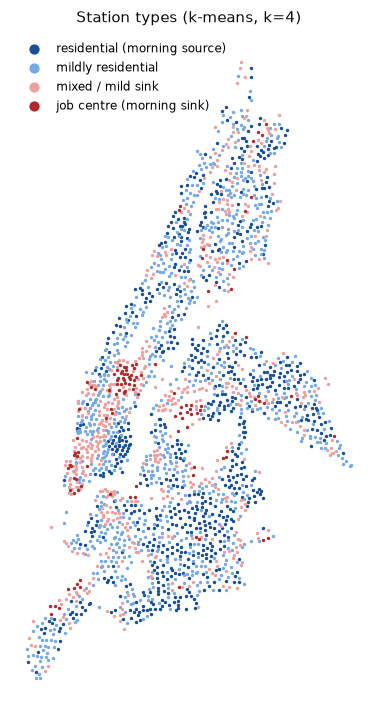

In [7]:
fig, ax = plt.subplots(figsize=(7, 8))
for c in range(K):
    m = labels == c
    ax.scatter(st.lng[m], st.lat[m], s=5, color=colors[c], label=names[c], linewidths=0)
style_map(ax, f"Station types (k-means, k={K})")
ax.legend(markerscale=3, fontsize=8, loc="upper left");

The types are spatially mixed at small scale but clearly organised at large scale: dense job-centre clusters in Midtown, Hudson Yards and FiDi, and residential stations dominating central Brooklyn, the Upper East/West Side and the South Bronx.

## 4. Hierarchical clustering (Ward)

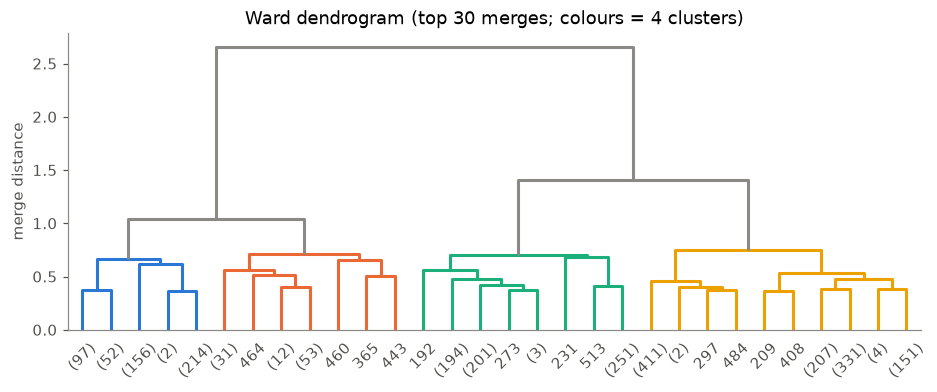

In [8]:
from scipy.cluster.hierarchy import set_link_color_palette

set_link_color_palette(CATEGORICAL[:K])
Lk = linkage(X.to_numpy(), method="ward")
fig, ax = plt.subplots(figsize=(10, 3.5))
dendrogram(Lk, truncate_mode="lastp", p=30, ax=ax, color_threshold=Lk[-K + 1, 2], above_threshold_color=NEUTRAL)
ax.set(title=f"Ward dendrogram (top 30 merges; colours = {K} clusters)", ylabel="merge distance"); ax.grid(False);

The Ward dendrogram shows the same picture. The last merge (k = 2 → 1) is clearly the largest, after which merge distances fall off gradually with no other obvious cut. That matches the indices preferring k = 2.

## 5. Station types inside the functional areas

In [9]:
im = comm.infomap.loc[ids].to_numpy()
mix = pd.crosstab(pd.Series(im, name="Infomap area"), pd.Series(labels, name="type").map(names), normalize="index")[[names[c] for c in range(K)]]
# Weekday-morning (6-10 am) imbalance of each area: net bikes gained per day / trip ends per day in those hours
prof = pd.read_parquet(PROCESSED / "profiles.parquet")
am = prof[(prof.day_type == "weekday") & prof.hour.between(6, 9) & prof.station_id.isin(ids)]
am = am.assign(area=am.station_id.map(comm.infomap)).groupby("area")[["arrivals", "departures"]].sum()
mix["am_net_bikes_per_day"] = (am.arrivals - am.departures).round(0)
mix["am_imbalance"] = ((am.arrivals - am.departures) / (am.arrivals + am.departures)).round(3)
mix["stations"] = pd.Series(im).value_counts()
mix.round(2).sort_values("am_imbalance")

type,residential (morning source),mildly residential,mixed / mild sink,job centre (morning sink),am_net_bikes_per_day,am_imbalance,stations
Infomap area,,,,,,,
7,0.48,0.28,0.20,0.04,-186.0,-0.17,168
4,0.32,0.49,0.16,0.03,-992.0,-0.12,235
8,0.28,0.50,0.21,0.01,-434.0,-0.11,114
1,0.38,0.39,0.20,0.02,-732.0,-0.08,476
6,0.43,0.35,0.20,0.03,-42.0,-0.06,192
5,0.40,0.29,0.23,0.08,-91.0,-0.04,196
2,0.27,0.45,0.25,0.03,-50.0,-0.03,427
9,0.26,0.47,0.21,0.06,-8.0,-0.03,97
12,0.00,0.67,0.33,0.00,-0.0,-0.02,3


**Every functional area contains every type.** Each area is a mix of residential and destination stations, which fits areas that are *self-contained*: people ride from home to shops, parks and work inside the same area. The exception is the **Manhattan core (area 3)**, which holds 14% job-centre stations (most of all areas) and is the only area that gains bikes in the weekday morning, about +1,660 per day. The areas that feed it run a deficit: the Upper West/East Side + Harlem (−990), the Brooklyn core (−730) and Williamsburg/Greenpoint (−430). Relative to traffic, area-level imbalances are small (at most 17% of trip ends in those hours).

In [10]:
# Station-level vs area-level imbalance: how much of the morning imbalance cancels out inside areas?
s_am = prof[(prof.day_type == "weekday") & prof.hour.between(6, 9) & prof.station_id.isin(ids)].groupby("station_id")[["arrivals", "departures"]].sum()
station_abs = (s_am.arrivals - s_am.departures).abs().sum()
area_abs = (am.arrivals - am.departures).abs().sum()
geo = pd.Series(KMeans(len(np.unique(im)), n_init=10, random_state=0).fit_predict(np.c_[st.lat, st.lng * np.cos(np.radians(40.7))]), index=ids)
geo_net = s_am.assign(g=geo).groupby("g")[["arrivals", "departures"]].sum()
print(f"sum of |net| over stations:         {station_abs:8.0f} bikes per weekday morning")
print(f"sum of |net| over Infomap areas:    {area_abs:8.0f}  ({area_abs / station_abs:.0%} of station level)")
print(f"sum of |net| over geographic areas: {(geo_net.arrivals - geo_net.departures).abs().sum():8.0f}  (same k, k-means on coordinates)")

sum of |net| over stations:            15276 bikes per weekday morning
sum of |net| over Infomap areas:        4204  (28% of station level)
sum of |net| over geographic areas:     3295  (same k, k-means on coordinates)


**Self-contained in trips is not the same as balanced in bikes.** Inside the Infomap areas, 72% of the station-level morning imbalance cancels out: a residential station's lost bikes are partly the job-centre station's gained bikes in the same area. But geographic areas with the same number of pieces cancel even more (78%). Why: Infomap draws its borders where *few* trips cross, but the trips that do cross, mostly morning commutes from Brooklyn and the Upper West/East Side into the core, all go the same way. So the imbalance that is left gathers at the area borders. For rebalancing (phase 2), this means the Infomap areas tell you *where riders stay*, but the bikes needed for the morning rush still have to move *between* areas, especially into the Manhattan core.

In [11]:
pd.DataFrame({"station_id": ids, "profile_type": labels, "profile_type_name": pd.Series(labels).map(names).to_numpy()}).to_parquet(
    PROCESSED / "station_profile_types.parquet", index=False)